# Final hierarchical Bayesian SLAM model

This notebook performs the single final refit selected by the overnight
within-user temporal search:

- nonlinear recency spline;
- nonlinear exposure-history spline;
- IRT-style user-ability × token-difficulty interactions;
- empirical Beta smoothing with strength 5;
- numeric, categorical, and hierarchical scales of 0.35;
- rank-2 user × skill mastery;
- ADVI learning rate 0.01 and batch size 8,192.

It trains on the complete `fr_en` training set, evaluates once on the official
development labels, and saves the posterior, preprocessing metadata,
predictions, metrics, convergence plot, reliability diagram, and risk-coverage
curve. No hyperparameter is changed after viewing these results.


## How to read this notebook

This is the final, locked refit of the project's hierarchical Bayesian error
model. The notebook is organized as a reproducible pipeline:

1. Parse SLAM into one row per token.
2. Build modular, leakage-safe feature families.
3. Apply the selected smoothing, nonlinear recency/history terms, and IRT-style
   ability-difficulty interactions.
4. Fit a partially pooled Bayesian logistic model with minibatch ADVI.
5. Propagate posterior uncertainty into predictions, calibration, and
   risk-coverage diagnostics.
6. Save a signed bundle of posterior, predictions, preprocessing, and metrics.

Comments labeled **PREQUENTIAL STEP** mark the most important leakage controls:
features are recorded using past information before the current exercise is
allowed to update any history. Optional feature blocks remain in the notebook
to document negative ablations, even when they are disabled in the final model.


## 1. Thread settings — run before numerical imports


In [22]:
# Configure numerical libraries before importing NumPy/PyMC.
# These environment variables limit competing thread pools so ADVI does not
# oversubscribe the CPU and become slower or less reproducible.

import os

FINAL_THREADS = max(1, min(8, (os.cpu_count() or 4) - 1))
for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "NUMBA_NUM_THREADS",
]:
    os.environ[variable] = str(FINAL_THREADS)

print("Requested numerical threads:", FINAL_THREADS)


Requested numerical threads: 8


## 1. Configuration

> **How to use this cell:** Feature blocks and Bayesian extensions are
> switches. The official final configuration should remain locked unless a new
> training-only validation experiment is being conducted.


In [23]:
# Central project configuration.
# Change feature families and optional Bayesian structures here rather than
# editing downstream model code. The selected final hyperparameters are fixed
# later in FINAL_CONFIGURATION so the official development set is evaluated
# only after model selection is complete.

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd


DATA_DIR = Path(
    r"C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french"
)
TRAIN_PATH = DATA_DIR / "fr_en.slam.20190204.train"
DEV_PATH = DATA_DIR / "fr_en.slam.20190204.dev"
DEV_KEY_PATH = DATA_DIR / "fr_en.slam.20190204.dev.key"
PROCESSED_DIR = DATA_DIR / "processed"

RANDOM_SEED = 2026

# This is the only list you edit to turn feature families on or off.
# Order matters when one block uses columns created by another block.
# Feature blocks execute top-to-bottom because later history blocks depend on earlier columns.
ENABLED_FEATURE_BLOCKS = [
    "linguistic",
    # "word_cognate",  # tested; negligible held-out improvement
    "skill_history",
    "forgetting_curve",
    "causal_user_ability",
    "global_skill_difficulty",
    # "recent_user_performance",
    # "session_fatigue",
]

# Final structural configuration selected by the 64-model screening grid.
# token_pos_hierarchy is intentionally excluded from the winning model.
# These switches alter hierarchical structure rather than adding ordinary columns.
ENABLED_BAYESIAN_EXTENSIONS = [
    "user_recency_slopes",       # also represents user-specific forgetting
    "user_format_slopes",
    # "token_pos_hierarchy",
    "morphology_hierarchy",
    "token_learning_slopes",
    "user_skill_mastery_low_rank",
]

# Posterior-guided pruning. These columns are still created by their feature
# blocks, but are excluded from both the L2 and Bayesian design matrices.
# Keep negatively signed predictors when they are informative: a negative
# coefficient means lower error odds, not worse predictive value.
# Exclusion is based on conditional posterior contribution, not coefficient sign.
EXCLUDED_NUMERIC_FEATURES = [
    "has_digit",                              # 95% interval crossed zero
    "log1p_decayed_prior_errors_7d",         # negligible conditional effect
    "log1p_average_exposure_spacing_days",   # very small conditional effect
    "log1p_maximum_exposure_spacing_days",   # redundant spacing summary
    "user_has_prior_history",                # redundant with history count
    "token_char_length",                     # very small conditional effect
]

# These morphology families had posterior hierarchy scales near zero. Stronger
# families (Definite, Gender, Number, Person, and PronType) remain enabled.
EXCLUDED_CATEGORICAL_FEATURES = [
    "morph_Mood",
    "morph_Reflex",
    "morph_Tense",
    "morph_VerbForm",
    "morph_fPOS",
]

USER_SKILL_MASTERY_LATENT_DIM = 2

# Full final-model fitting settings.
# ADVI controls optimization effort; posterior draws control Monte Carlo precision after fitting.
ADVI_ITERATIONS = 30_000
ADVI_BATCH_SIZE = 8_192
POSTERIOR_DRAWS = 1_000
PREDICTION_CHUNK_SIZE = 5_000

# Exercise-level expanding-window validation. This rebuilds all enabled
# features inside every fold, so it is intentionally more expensive.
# Keep expensive experiment flags off during an ordinary final-refit run.
RUN_FIVE_FOLD_CV = False
CROSS_VALIDATION_FOLDS = 5

# Five full hierarchical Bayesian refits using the same exercise-level
# expanding-window folds. Results are checkpointed after every fold.
RUN_BAYESIAN_FIVE_FOLD_CV = True
BAYESIAN_CV_FOLDS = 5
BAYESIAN_CV_ADVI_ITERATIONS = ADVI_ITERATIONS
BAYESIAN_CV_BATCH_SIZE = ADVI_BATCH_SIZE
BAYESIAN_CV_POSTERIOR_DRAWS = POSTERIOR_DRAWS

# Exact independent-background SHAP values for the fitted linear L2 model.
RUN_L2_SHAP_ANALYSIS = True
SHAP_BACKGROUND_SIZE = 20_000
SHAP_EXPLANATION_SIZE = 10_000
SHAP_CHUNK_SIZE = 1_000

# Posterior-aware parameter and additive contribution analysis for the
# hierarchical Bayesian model (the Bayesian analogue of global SHAP).
RUN_BAYESIAN_PARAMETER_ANALYSIS = True
BAYESIAN_ANALYSIS_OBSERVATIONS = 10_000
BAYESIAN_ANALYSIS_DRAWS = 300

# Resumable overnight hyperparameter search on the final forward-validation
# fold. Posterior draws are held fixed because they control Monte Carlo
# precision rather than model capacity.
RUN_OVERNIGHT_BAYESIAN_PARAMETER_GRID = False
OVERNIGHT_GRID_POSTERIOR_DRAWS = 500
OVERNIGHT_GRID_FOLD = 5

# Fast leakage-safe screening of Beta smoothing for the dominant global
# difficulty predictors. This uses one forward fold and a numeric-only L2
# model; the winner should subsequently be confirmed in the Bayesian model.
RUN_QUICK_BETA_SMOOTHING_SCREEN = True
BETA_SMOOTHING_SCREEN_FOLD = 5
BETA_SMOOTHING_PRIOR_STRENGTHS = [2, 5, 10, 25, 50, 100, 250]

# This grid is retained as an audit trail of the training-only model search.
OVERNIGHT_BAYESIAN_PARAMETER_GRID = [
    # Baseline and optimizer/minibatch sensitivity.
    dict(name="baseline", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="iterations_20k", iterations=20_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="iterations_45k", iterations=45_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="batch_4096", iterations=30_000, batch_size=4_096,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="batch_16384", iterations=30_000, batch_size=16_384,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="learning_rate_005", iterations=30_000, batch_size=8_192,
         learning_rate=0.005, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="long_lr005", iterations=45_000, batch_size=8_192,
         learning_rate=0.005, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),

    # Fixed-effect shrinkage.
    dict(name="numeric_prior_035", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.35,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="numeric_prior_075", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.75,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="categorical_scale_035", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.35, hierarchy_prior=0.50, mastery_rank=2),
    dict(name="categorical_scale_075", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.75, hierarchy_prior=0.50, mastery_rank=2),

    # Hierarchical shrinkage and mastery capacity.
    dict(name="hierarchy_prior_025", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.25, mastery_rank=2),
    dict(name="hierarchy_prior_075", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.75, mastery_rank=2),
    dict(name="mastery_rank_1", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=1),
    dict(name="mastery_rank_3", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=3),
    dict(name="mastery_rank_4", iterations=30_000, batch_size=8_192,
         learning_rate=0.010, numeric_prior=0.50,
         categorical_scale=0.50, hierarchy_prior=0.50, mastery_rank=4),

    # One deliberately higher-capacity, more conservative optimizer candidate.
    dict(name="long_rank3_lr005", iterations=45_000, batch_size=4_096,
         learning_rate=0.005, numeric_prior=0.35,
         categorical_scale=0.35, hierarchy_prior=0.35, mastery_rank=3),
]

for required_path in [TRAIN_PATH, DEV_PATH, DEV_KEY_PATH]:
    assert required_path.is_file(), f"Missing file: {required_path}"

print("Enabled feature blocks:", ENABLED_FEATURE_BLOCKS)
print("Enabled Bayesian extensions:", ENABLED_BAYESIAN_EXTENSIONS)
print("Excluded numeric features:", EXCLUDED_NUMERIC_FEATURES)
print("Excluded categorical features:", EXCLUDED_CATEGORICAL_FEATURES)


Enabled feature blocks: ['linguistic', 'skill_history', 'forgetting_curve', 'causal_user_ability', 'global_skill_difficulty']
Enabled Bayesian extensions: ['user_recency_slopes', 'user_format_slopes', 'morphology_hierarchy', 'token_learning_slopes', 'user_skill_mastery_low_rank']
Excluded numeric features: ['has_digit', 'log1p_decayed_prior_errors_7d', 'log1p_average_exposure_spacing_days', 'log1p_maximum_exposure_spacing_days', 'user_has_prior_history', 'token_char_length']
Excluded categorical features: ['morph_Mood', 'morph_Reflex', 'morph_Tense', 'morph_VerbForm', 'morph_fPOS']


## 2. SLAM parser

> **Data contract:** One output row represents one exercise token. Exercise
> metadata are repeated across its tokens, while labels are token-specific.


In [24]:
# Raw-data parser.
# SLAM stores exercise metadata on comment lines followed by one line per token.
# This cell converts that hierarchical text format into a rectangular table
# with one row per token while preserving exercise, session, and learner IDs.

"""Parse Duolingo SLAM files into one-row-per-token pandas DataFrames."""

from __future__ import annotations

from pathlib import Path
from typing import Any

import pandas as pd


# Columns common to every split; morphology adds dynamic morph_* columns later.
FIXED_COLUMNS = (
    "instance_id",
    "session_id",
    "exercise_id",
    "exercise_index",
    "token_index",
    "token",
    "token_lower",
    "part_of_speech",
    "morphology",
    "dependency_label",
    "dependency_edge_head",
    "prompt",
    "user",
    "countries",
    "days",
    "client",
    "session",
    "format",
    "time",
    "label",
    "course",
    "split",
)

CATEGORICAL_COLUMNS = (
    "part_of_speech",
    "dependency_label",
    "countries",
    "client",
    "session",
    "format",
    "course",
    "split",
)


def _infer_split(path: Path) -> str:
    """Infer train/dev/test from a standard SLAM filename."""
    name = path.name.lower()
    for split in ("train", "dev", "test"):
        if split in name:
            return split
    return "unknown"


def _infer_course(path: Path) -> str:
    """Infer the course prefix, such as fr_en, from a SLAM filename."""
    first_component = path.name.split(".", maxsplit=1)[0]
    return first_component if "_" in first_component else "unknown"


def _parse_metadata(line: str) -> dict[str, Any]:
    """Parse a non-prompt metadata line beginning with '# '."""
    metadata: dict[str, Any] = {}
    for field in line[2:].split():
        key, value = field.split(":", maxsplit=1)
        if key == "days":
            metadata[key] = float(value)
        elif key == "time":
            metadata[key] = None if value == "null" else int(value)
        else:
            metadata[key] = value
    return metadata


def optimize_slam_dtypes(frame: pd.DataFrame) -> pd.DataFrame:
    """Reduce memory usage while retaining nullable values."""
    for column in CATEGORICAL_COLUMNS:
        if column in frame:
            frame[column] = frame[column].astype("category")

    for column in frame.columns:
        if column.startswith("morph_"):
            if column == "morph_Person":
                frame[column] = pd.to_numeric(frame[column], errors="coerce").astype("Int8")
            else:
                frame[column] = frame[column].astype("category")

    frame["exercise_index"] = frame["exercise_index"].astype("int16")
    frame["token_index"] = frame["token_index"].astype("int16")
    frame["dependency_edge_head"] = frame["dependency_edge_head"].astype("int16")
    frame["days"] = frame["days"].astype("float32")
    frame["time"] = pd.array(frame["time"], dtype="Int32")
    frame["label"] = pd.array(frame["label"], dtype="Int8")
    return frame


def load_slam_dataframe(
    filename: str | Path,
    *,
    split: str | None = None,
    course: str | None = None,
    optimize_dtypes: bool = True,
) -> pd.DataFrame:
    """Load a SLAM train/dev/test file as one row per token.

    The parser retains raw morphology in ``morphology`` and also expands each
    morphological attribute into a ``morph_<name>`` column. Train files carry
    their labels in the final token column; unlabeled dev/test rows receive a
    nullable ``label`` column so all splits share the same schema.
    """
    path = Path(filename)
    if not path.is_file():
        raise FileNotFoundError(path)

    split = split or _infer_split(path)
    course = course or _infer_course(path)
    columns: dict[str, list[Any]] = {column: [] for column in FIXED_COLUMNS}
    morphology_columns: dict[str, list[Any]] = {}
    exercise_metadata: dict[str, Any] = {}
    expected_token_fields: int | None = None

    # Stream the large text file instead of loading it entirely into memory.
    with path.open("r", encoding="utf-8") as source:
        for line_number, raw_line in enumerate(source, start=1):
            line = raw_line.strip()

            # A blank line terminates the current exercise metadata block.
            if not line:
                exercise_metadata = {}
                continue

            # Prompt text is kept separate because it may contain spaces.
            if line.startswith("# prompt:"):
                exercise_metadata["prompt"] = line.split(":", maxsplit=1)[1]
                continue

            # Other comment lines contain compact key:value exercise metadata.
            if line.startswith("#"):
                exercise_metadata.update(_parse_metadata(line))
                continue

            # Token rows have six fields without labels and seven with labels.
            fields = line.split()
            if expected_token_fields is None:
                expected_token_fields = len(fields)
                if expected_token_fields not in (6, 7):
                    raise ValueError(
                        f"{path.name}:{line_number}: expected 6 or 7 token fields, "
                        f"found {expected_token_fields}"
                    )
            elif len(fields) != expected_token_fields:
                raise ValueError(
                    f"{path.name}:{line_number}: expected {expected_token_fields} "
                    f"token fields, found {len(fields)}"
                )

            required_metadata = {"user", "countries", "days", "client", "session", "format", "time"}
            missing_metadata = required_metadata - exercise_metadata.keys()
            if missing_metadata:
                raise ValueError(
                    f"{path.name}:{line_number}: token appears before metadata fields "
                    f"{sorted(missing_metadata)}"
                )

            instance_id, token, part_of_speech, morphology, dependency_label, edge_head = fields[:6]
            label = int(fields[6]) if len(fields) == 7 else None
            row_index = len(columns["instance_id"])

            columns["instance_id"].append(instance_id)
            # SLAM instance IDs encode session, exercise, and token positions.
            columns["session_id"].append(instance_id[:8])
            columns["exercise_id"].append(instance_id[:10])
            columns["exercise_index"].append(int(instance_id[8:10]))
            columns["token_index"].append(int(instance_id[10:12]))
            columns["token"].append(token)
            columns["token_lower"].append(token.casefold())
            columns["part_of_speech"].append(part_of_speech)
            columns["morphology"].append(morphology)
            columns["dependency_label"].append(dependency_label)
            columns["dependency_edge_head"].append(int(edge_head))
            columns["prompt"].append(exercise_metadata.get("prompt"))
            columns["user"].append(exercise_metadata["user"])
            columns["countries"].append(exercise_metadata["countries"])
            columns["days"].append(exercise_metadata["days"])
            columns["client"].append(exercise_metadata["client"])
            columns["session"].append(exercise_metadata["session"])
            columns["format"].append(exercise_metadata["format"])
            columns["time"].append(exercise_metadata["time"])
            columns["label"].append(label)
            columns["course"].append(course)
            columns["split"].append(split)

            # Backfill missing morphology attributes so all lists stay row-aligned.
            for values in morphology_columns.values():
                values.append(None)

            for item in morphology.split("|"):
                key, value = item.split("=", maxsplit=1)
                column_name = f"morph_{key}"
                if column_name not in morphology_columns:
                    morphology_columns[column_name] = [None] * row_index + [value]
                else:
                    morphology_columns[column_name][-1] = value

    if not columns["instance_id"]:
        raise ValueError(f"No token records found in {path}")

    # Construct once after parsing; repeated DataFrame appends would be much slower.
    frame = pd.DataFrame({**columns, **morphology_columns})
    if optimize_dtypes:
        frame = optimize_slam_dtypes(frame)
    return frame


def load_label_file(filename: str | Path) -> pd.Series:
    """Load a SLAM .key or .pred file as an instance-ID-indexed Series."""
    path = Path(filename)
    labels = pd.read_csv(
        path,
        sep=r"\s+",
        names=["instance_id", "label"],
        index_col="instance_id",
        dtype={"instance_id": "string", "label": "float64"},
    )
    if not labels.index.is_unique:
        raise ValueError(f"Duplicate instance IDs in {path}")
    return labels["label"]



## 3. Load immutable raw token tables

> **Why immutable?** Rebuilding every experiment from the same raw tables
> prevents notebook execution order from contaminating later feature ablations.


In [25]:
# Load immutable raw tables once.
# Every feature experiment starts from these objects, which prevents a disabled
# feature block from leaving stale columns behind in a later run.

train_tokens_raw = load_slam_dataframe(TRAIN_PATH, split="train")
dev_tokens_raw = load_slam_dataframe(DEV_PATH, split="dev")
dev_key = load_label_file(DEV_KEY_PATH)

assert train_tokens_raw["instance_id"].is_unique
assert dev_tokens_raw["instance_id"].is_unique
assert train_tokens_raw["label"].notna().all()
assert dev_tokens_raw["label"].isna().all()
assert set(dev_tokens_raw["instance_id"]) == set(dev_key.index)

print("Train tokens:", train_tokens_raw.shape)
print("Development tokens:", dev_tokens_raw.shape)
print("Training error rate:", f'{train_tokens_raw["label"].mean():.4%}')


Train tokens: (926646, 32)
Development tokens: (137564, 32)
Training error rate: 16.2266%


## 4. Feature registry

> **Design pattern:** Each feature family is self-contained and declares
> exactly which generated columns enter the numeric and categorical models.


In [26]:
# Lightweight feature-block registry.
# Each block returns its transformed frame plus explicit numeric/categorical
# manifests. This keeps feature engineering modular and makes ablations a
# one-line change in ENABLED_FEATURE_BLOCKS.

from dataclasses import dataclass
from typing import Callable


@dataclass
class FeatureOutput:
    frame: pd.DataFrame
    numeric: tuple[str, ...] = ()
    categorical: tuple[str, ...] = ()


@dataclass
class FeatureBlock:
    name: str
    transform: Callable[[pd.DataFrame], FeatureOutput]
    description: str


# Rerunning this cell deliberately resets the registry.
# The registry is the single source of truth for available feature families.
FEATURE_REGISTRY: dict[str, FeatureBlock] = {}


def register_feature_block(
    name: str,
    transform: Callable[[pd.DataFrame], FeatureOutput],
    description: str,
) -> None:
    """Register or replace one named feature block."""
    FEATURE_REGISTRY[name] = FeatureBlock(
        name=name,
        transform=transform,
        description=description,
    )


# Preserve feature order because coefficient coordinates depend on it.
def unique_in_order(values):
    """Deduplicate strings without changing their order."""
    return list(dict.fromkeys(values))


## 5A. Linguistic and metadata features

This block also declares model-ready categorical columns. Its final line registers the block.

> These variables capture token form, syntax, morphology, timing, and
> exercise context. They require no historical outcomes.


In [27]:
# Static linguistic and metadata predictors.
# These features describe the current token and exercise only; they do not use
# outcomes and therefore cannot leak the current label.

def make_linguistic_features(dataframe: pd.DataFrame) -> FeatureOutput:
    frame = dataframe.copy()

    token = frame["token"].astype("string")
    prompt = frame["prompt"].astype("string").fillna("")

    # In this project, the normalized token is the item/skill used by IRT-like effects.
    frame["skill"] = frame["token_lower"].astype("string")
    frame["token_char_length"] = token.str.len().fillna(0).astype("int16")
    frame["prompt_char_length"] = prompt.str.len().astype("int16")
    frame["prompt_word_count"] = prompt.str.split().str.len().astype("int16")
    frame["morph_feature_count"] = (
        frame["morphology"].astype("string").str.count(r"\|").fillna(-1) + 1
    ).clip(lower=0).astype("int8")

    frame["is_dependency_root"] = (
        frame["dependency_label"].astype("string").eq("ROOT")
        | frame["dependency_edge_head"].eq(0)
    ).astype("int8")

    # Dependency distance approximates syntactic complexity around the token.
    frame["dependency_distance"] = np.where(
        frame["dependency_edge_head"].eq(0),
        0,
        np.abs(frame["token_index"] - frame["dependency_edge_head"]),
    ).astype("int16")

    frame["is_sentence_initial"] = frame["token_index"].eq(1).astype("int8")
    frame["is_capitalized"] = token.str[0].str.isupper().fillna(False).astype("int8")
    frame["has_digit"] = token.str.contains(r"\d", regex=True, na=False).astype("int8")
    frame["has_non_ascii"] = token.str.contains(
        r"[^\x00-\x7F]", regex=True, na=False
    ).astype("int8")
    frame["days_log1p"] = np.log1p(frame["days"].clip(lower=0)).astype("float32")
    # Preserve missingness explicitly before replacing missing response times with zero.
    frame["time_missing"] = frame["time"].isna().astype("int8")
    frame["time_log1p"] = np.log1p(
        frame["time"].fillna(0).clip(lower=0)
    ).astype("float32")

    numeric = (
        "token_char_length",
        "prompt_char_length",
        "prompt_word_count",
        "morph_feature_count",
        "is_dependency_root",
        "dependency_distance",
        "is_sentence_initial",
        "is_capitalized",
        "has_digit",
        "has_non_ascii",
        "days_log1p",
        "time_missing",
        "time_log1p",
    )

    categorical = [
        "user",
        "skill",
        "format",
        "client",
        "session",
        "countries",
        "part_of_speech",
        "dependency_label",
    ]
    # Morphology columns are discovered dynamically because not every file has every attribute.
    categorical += [
        column
        for column in frame.columns
        if column.startswith("morph_") and column != "morph_feature_count"
    ]

    for column in categorical:
        frame[column] = (
            frame[column]
            .astype("string")
            .fillna("__MISSING__")
            .astype("category")
        )

    return FeatureOutput(
        frame=frame,
        numeric=tuple(numeric),
        categorical=tuple(categorical),
    )


register_feature_block(
    "linguistic",
    make_linguistic_features,
    "Token, prompt, syntax, morphology, time, and metadata features.",
)


## 5B. Word-form and French-English cognate features

Character affixes and spelling indicators describe the French token. Cognate features compare an accent-normalized French token with every English prompt word and keep the strongest edit, prefix, and suffix match. Token frequency is learned from the training partition only.

> This optional family was tested and retained in the code for transparency,
> but it was excluded from the final configuration after negligible validation gain.


In [28]:
# Optional word-form and cognate predictors.
# This block normalizes French accents and punctuation, compares French tokens
# with English prompt words, and exposes prefixes/suffixes and edit similarity.
# It remains registered for reproducible ablation even though it is disabled in
# the selected final feature set.

import unicodedata


def _normalize_word_form(value) -> str:
    """Casefold, remove accents, and retain ASCII letters."""
    if pd.isna(value):
        return ""
    decomposed = unicodedata.normalize("NFKD", str(value).casefold())
    without_accents = "".join(
        character
        for character in decomposed
        if not unicodedata.combining(character)
    )
    return "".join(re.findall(r"[a-z]+", without_accents))


def _normalize_prompt_words(value) -> str:
    """Return normalized English prompt words separated by one space."""
    if pd.isna(value):
        return ""
    decomposed = unicodedata.normalize("NFKD", str(value).casefold())
    without_accents = "".join(
        character
        for character in decomposed
        if not unicodedata.combining(character)
    )
    return " ".join(re.findall(r"[a-z]+", without_accents))


# Exact edit distance is computed on short normalized words, so dynamic programming is inexpensive.
def _levenshtein_distance(left: str, right: str) -> int:
    """Compute edit distance with two short dynamic-programming rows."""
    if left == right:
        return 0
    if len(left) < len(right):
        left, right = right, left
    if not right:
        return len(left)

    previous = list(range(len(right) + 1))
    for left_index, left_character in enumerate(left, start=1):
        current = [left_index]
        for right_index, right_character in enumerate(right, start=1):
            current.append(
                min(
                    current[-1] + 1,
                    previous[right_index] + 1,
                    previous[right_index - 1]
                    + (left_character != right_character),
                )
            )
        previous = current
    return previous[-1]


def _shared_prefix_length(left: str, right: str) -> int:
    length = 0
    for left_character, right_character in zip(left, right):
        if left_character != right_character:
            break
        length += 1
    return length


def _shared_suffix_length(left: str, right: str) -> int:
    length = 0
    for left_character, right_character in zip(reversed(left), reversed(right)):
        if left_character != right_character:
            break
        length += 1
    return length


# Compare one French token with one candidate prompt word.
def _cognate_pair_metrics(token: str, prompt: str) -> tuple[float, int, int]:
    words = prompt.split()
    if not token or not words:
        return 0.0, 0, 0

    similarities = [
        1.0
        - _levenshtein_distance(token, word)
        / max(len(token), len(word))
        for word in words
    ]
    prefix_length = max(_shared_prefix_length(token, word) for word in words)
    suffix_length = max(_shared_suffix_length(token, word) for word in words)
    return max(similarities), prefix_length, suffix_length


# Aggregate the best cognate match across all English prompt words.
def make_word_cognate_features(dataframe: pd.DataFrame) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_word_cognate_row"] = np.arange(len(frame), dtype=np.int64)

    token_text = frame["token_lower"].astype("string").fillna("")
    prompt_text = frame["prompt"].astype("string").fillna("")

    token_normalization = {
        value: _normalize_word_form(value)
        for value in token_text.unique().tolist()
    }
    prompt_normalization = {
        value: _normalize_prompt_words(value)
        for value in prompt_text.unique().tolist()
    }
    frame["_word_token_normalized"] = token_text.map(token_normalization)
    frame["_word_prompt_normalized"] = prompt_text.map(prompt_normalization)

    # Only about one row per distinct token-prompt pair needs edit-distance work.
    pair_metrics = frame[
        ["_word_token_normalized", "_word_prompt_normalized"]
    ].drop_duplicates(ignore_index=True)
    computed_metrics = [
        _cognate_pair_metrics(token, prompt)
        for token, prompt in pair_metrics.itertuples(index=False, name=None)
    ]
    pair_metrics[
        [
            "normalized_prompt_edit_similarity",
            "shared_prompt_prefix_length",
            "shared_prompt_suffix_length",
        ]
    ] = pd.DataFrame(computed_metrics, index=pair_metrics.index)

    frame = frame.merge(
        pair_metrics,
        on=["_word_token_normalized", "_word_prompt_normalized"],
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = frame.sort_values("_word_cognate_row", kind="stable").reset_index(
        drop=True
    )

    frame["normalized_prompt_edit_similarity"] = frame[
        "normalized_prompt_edit_similarity"
    ].astype("float32")
    frame["shared_prompt_prefix_length"] = frame[
        "shared_prompt_prefix_length"
    ].astype("int16")
    frame["shared_prompt_suffix_length"] = frame[
        "shared_prompt_suffix_length"
    ].astype("int16")
    frame["prompt_has_english_words"] = frame[
        "_word_prompt_normalized"
    ].ne("").astype("int8")

    frame["french_accent_count"] = token_text.str.count(
        r"[àâäçéèêëîïôöùûüÿ]"
    ).astype("int8")
    frame["has_apostrophe"] = token_text.str.contains(
        r"['’]", regex=True, na=False
    ).astype("int8")
    frame["has_hyphen"] = token_text.str.contains(
        r"[-‐‑‒–—]", regex=True, na=False
    ).astype("int8")

    training_token_counts = (
        token_text.loc[frame["_partition"].eq("train")].value_counts()
    )
    frame["train_token_frequency"] = (
        token_text.map(training_token_counts).fillna(0).astype("int32")
    )
    frame["log1p_train_token_frequency"] = np.log1p(
        frame["train_token_frequency"]
    ).astype("float32")

    categorical = []
    for affix_length in (1, 2, 3):
        prefix_column = f"token_prefix_{affix_length}"
        suffix_column = f"token_suffix_{affix_length}"
        frame[prefix_column] = (
            frame["_word_token_normalized"]
            .str[:affix_length]
            .replace("", "__EMPTY__")
            .astype("category")
        )
        frame[suffix_column] = (
            frame["_word_token_normalized"]
            .str[-affix_length:]
            .replace("", "__EMPTY__")
            .astype("category")
        )
        categorical.extend([prefix_column, suffix_column])

    numeric = (
        "french_accent_count",
        "has_apostrophe",
        "has_hyphen",
        "prompt_has_english_words",
        "normalized_prompt_edit_similarity",
        "shared_prompt_prefix_length",
        "shared_prompt_suffix_length",
        "log1p_train_token_frequency",
    )

    frame = frame.drop(
        columns=[
            "_word_cognate_row",
            "_word_token_normalized",
            "_word_prompt_normalized",
        ]
    )
    return FeatureOutput(
        frame=frame,
        numeric=numeric,
        categorical=tuple(categorical),
    )


register_feature_block(
    "word_cognate",
    make_word_cognate_features,
    "French word form, English-prompt cognate similarity, and training frequency.",
)


## 5C. Leakage-safe user-skill history

All label-derived values are shifted at the exercise level. Tokens in the current exercise cannot use labels from that exercise.

> History is aggregated at exercise level before being merged back to
> tokens. This prevents tokens in the same exercise from leaking outcomes to one another.


In [29]:
# Leakage-safe learner-by-token history.
# All cumulative quantities are recorded before the current exercise outcomes
# are added, so every row represents information available at prediction time.

def make_skill_history_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_skill_history_row"] = np.arange(len(frame), dtype=np.int64)

    # Exercise ID is part of the event key so all tokens in one exercise share the same entering history.
    keys = ["user", "token_lower", "exercise_id"]

    # Collapse token rows to exposure events before calculating cumulative history.
    exercise = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            exposure_day=("days", "first"),
            event_order=("_skill_history_row", "min"),
            event_exposures=("instance_id", "size"),
            event_labeled_exposures=("label", "count"),
            event_errors=("label", lambda values: float(values.sum(skipna=True))),
        )
        .reset_index()
        .sort_values(
            ["user", "token_lower", "exposure_day", "event_order"],
            kind="stable",
        )
    )

    groups = exercise.groupby(
        ["user", "token_lower"],
        sort=False,
        observed=True,
        dropna=False,
    )

    # Subtract the current event: cumsum alone would leak current outcomes/exposures.
    exercise["prior_exposures"] = (
        groups["event_exposures"].cumsum() - exercise["event_exposures"]
    )
    exercise["prior_labeled_exposures"] = (
        groups["event_labeled_exposures"].cumsum()
        - exercise["event_labeled_exposures"]
    )
    exercise["prior_errors"] = (
        groups["event_errors"].cumsum() - exercise["event_errors"]
    )

    previous_day = groups["exposure_day"].shift(1)
    exercise["has_prior_exposure"] = previous_day.notna().astype("int8")
    exercise["time_since_last_exposure_days"] = (
        exercise["exposure_day"] - previous_day
    ).clip(lower=0).fillna(0)

    # Beta(alpha,beta) smoothing supplies a finite prior rate for first exposure.
    exercise["prior_error_rate"] = (
        exercise["prior_errors"] + alpha
    ) / (
        exercise["prior_labeled_exposures"] + alpha + beta
    )

    exercise["log1p_prior_exposures"] = np.log1p(
        exercise["prior_exposures"]
    )
    exercise["log1p_time_since_last_exposure"] = np.log1p(
        exercise["time_since_last_exposure_days"]
    )

    created = [
        "prior_exposures",
        "prior_labeled_exposures",
        "prior_errors",
        "prior_error_rate",
        "has_prior_exposure",
        "time_since_last_exposure_days",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
    ]

    # Merge event-level features back to tokens, then restore the original token order.
    frame = frame.merge(
        exercise[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_skill_history_row", kind="stable")
        .drop(columns="_skill_history_row")
        .reset_index(drop=True)
    )

    for column in ["prior_exposures", "prior_labeled_exposures", "prior_errors"]:
        frame[column] = frame[column].astype("int32")

    for column in [
        "prior_error_rate",
        "time_since_last_exposure_days",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
    ]:
        frame[column] = frame[column].astype("float32")

    # These are the nonredundant columns supplied to both models.
    numeric = (
        "prior_error_rate",
        "log1p_prior_exposures",
        "log1p_time_since_last_exposure",
        "has_prior_exposure",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "skill_history",
    make_skill_history_features,
    "Shifted user-token error history, exposure, and forgetting features.",
)


## 5C. Forgetting-curve and exposure-spacing features

These features maintain decayed error/success evidence separately for each user-token pair. State is decayed to the current exercise time before the current labels are observed, so every value is leakage-safe.

> Decay features encode the intuition that recent practice should matter
> more than equally old practice, while spacing summaries describe repetition schedules.


In [30]:
# Forgetting-curve summaries.
# Exponentially decayed errors and successes represent memory traces at short
# (one-day) and longer (seven-day) time scales.

def make_forgetting_curve_features(
    dataframe: pd.DataFrame,
) -> FeatureOutput:
    # Dependency check makes feature-block ordering explicit.
    required = {
        "time_since_last_exposure_days",
        "has_prior_exposure",
    }
    missing = required.difference(dataframe.columns)
    if missing:
        raise KeyError(
            "forgetting_curve requires skill_history first; missing "
            f"{sorted(missing)}"
        )

    frame = dataframe.copy()
    frame["_forgetting_row"] = np.arange(len(frame), dtype=np.int64)

    keys = ["user", "token_lower", "exercise_id"]
    events = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            exposure_day=("days", "first"),
            event_order=("_forgetting_row", "min"),
            current_labeled_answers=("label", "count"),
            current_errors=(
                "label",
                lambda values: float(values.sum(skipna=True)),
            ),
        )
        .reset_index()
        .sort_values(
            ["user", "token_lower", "exposure_day", "event_order"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    n_events = len(events)
    decayed_errors_1d = np.zeros(n_events, dtype=np.float32)
    decayed_successes_1d = np.zeros(n_events, dtype=np.float32)
    decayed_errors_7d = np.zeros(n_events, dtype=np.float32)
    decayed_successes_7d = np.zeros(n_events, dtype=np.float32)
    average_spacing = np.zeros(n_events, dtype=np.float32)
    maximum_spacing = np.zeros(n_events, dtype=np.float32)

    # Maintain a separate decayed memory state for each learner-token pair.
    for positions in events.groupby(
        ["user", "token_lower"],
        sort=False,
        observed=True,
        dropna=False,
    ).indices.values():
        error_state_1d = 0.0
        success_state_1d = 0.0
        error_state_7d = 0.0
        success_state_7d = 0.0
        previous_day = None
        spacing_sum = 0.0
        spacing_count = 0
        spacing_max = 0.0

        for position in positions:
            current_day = float(events.at[position, "exposure_day"])

            if previous_day is not None:
                gap = max(current_day - previous_day, 0.0)
                decay_1d = np.exp(-gap / 1.0)
                decay_7d = np.exp(-gap / 7.0)

                error_state_1d *= decay_1d
                success_state_1d *= decay_1d
                error_state_7d *= decay_7d
                success_state_7d *= decay_7d

                spacing_sum += gap
                spacing_count += 1
                spacing_max = max(spacing_max, gap)

            # PREQUENTIAL STEP: snapshot the entering state before updating it.
            # Record state before incorporating labels from this exercise.
            decayed_errors_1d[position] = error_state_1d
            decayed_successes_1d[position] = success_state_1d
            decayed_errors_7d[position] = error_state_7d
            decayed_successes_7d[position] = success_state_7d
            average_spacing[position] = (
                spacing_sum / spacing_count if spacing_count else 0.0
            )
            maximum_spacing[position] = spacing_max

            current_errors = float(events.at[position, "current_errors"])
            current_answers = int(events.at[position, "current_labeled_answers"])
            current_successes = max(current_answers - current_errors, 0.0)

            # Only now may the current exercise update the state used by future exercises.
            error_state_1d += current_errors
            success_state_1d += current_successes
            error_state_7d += current_errors
            success_state_7d += current_successes
            previous_day = current_day

    events["decayed_prior_errors_1d"] = decayed_errors_1d
    events["decayed_prior_successes_1d"] = decayed_successes_1d
    events["decayed_prior_errors_7d"] = decayed_errors_7d
    events["decayed_prior_successes_7d"] = decayed_successes_7d
    events["average_exposure_spacing_days"] = average_spacing
    events["maximum_exposure_spacing_days"] = maximum_spacing

    created = [
        "decayed_prior_errors_1d",
        "decayed_prior_successes_1d",
        "decayed_prior_errors_7d",
        "decayed_prior_successes_7d",
        "average_exposure_spacing_days",
        "maximum_exposure_spacing_days",
    ]

    frame = frame.merge(
        events[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_forgetting_row", kind="stable")
        .drop(columns="_forgetting_row")
        .reset_index(drop=True)
    )

    # Zero the decay features for learners who have never seen the token.
    frame["recency_decay_1d"] = (
        frame["has_prior_exposure"]
        * np.exp(-frame["time_since_last_exposure_days"] / 1.0)
    ).astype("float32")
    frame["recency_decay_7d"] = (
        frame["has_prior_exposure"]
        * np.exp(-frame["time_since_last_exposure_days"] / 7.0)
    ).astype("float32")

    for column in created:
        frame[column] = frame[column].astype("float32")
        frame[f"log1p_{column}"] = np.log1p(
            frame[column].clip(lower=0)
        ).astype("float32")

    numeric = (
        "recency_decay_1d",
        "recency_decay_7d",
        "log1p_decayed_prior_errors_1d",
        "log1p_decayed_prior_successes_1d",
        "log1p_decayed_prior_errors_7d",
        "log1p_decayed_prior_successes_7d",
        "log1p_average_exposure_spacing_days",
        "log1p_maximum_exposure_spacing_days",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "forgetting_curve",
    make_forgetting_curve_features,
    "One- and seven-day decay, decayed outcomes, and exposure spacing.",
)


## 5D. Causal/online user ability

This is a temporally valid historical ability estimate, not a causal treatment-effect estimate. It uses only labels from earlier exercises. Higher `user_ability_log_odds` means lower historical error probability.

> The estimate is causal/online: the current exercise is subtracted from
> cumulative counts before ability is calculated.


In [31]:
# Online learner ability estimate.
# Ability is computed only from exercises completed earlier by the learner and
# is expressed as correct-versus-error log odds for compatibility with IRT.

def make_causal_user_ability_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_ability_row"] = np.arange(len(frame), dtype=np.int64)

    # Ability changes between exercises, not between tokens from the same exercise.
    exercise = (
        frame.groupby(
            ["user", "exercise_id"],
            sort=False,
            observed=True,
            dropna=False,
        )
        .agg(
            exposure_day=("days", "first"),
            event_order=("_ability_row", "min"),
            current_errors=("label", lambda values: float(values.sum(skipna=True))),
            current_labeled_tokens=("label", "count"),
        )
        .reset_index()
        .sort_values(["user", "exposure_day", "event_order"], kind="stable")
    )

    groups = exercise.groupby("user", sort=False, observed=True, dropna=False)
    # Shifted cumulative counts exclude the exercise being predicted.
    exercise["user_prior_errors"] = (
        groups["current_errors"].cumsum() - exercise["current_errors"]
    )
    exercise["user_prior_labeled_tokens"] = (
        groups["current_labeled_tokens"].cumsum()
        - exercise["current_labeled_tokens"]
    )

    exercise["user_prior_error_rate"] = (
        exercise["user_prior_errors"] + alpha
    ) / (
        exercise["user_prior_labeled_tokens"] + alpha + beta
    )

    error_probability = exercise["user_prior_error_rate"].clip(1e-6, 1 - 1e-6)
    # Positive values mean more prior success than error; this matches the IRT ability direction.
    exercise["user_ability_log_odds"] = np.log(
        (1.0 - error_probability) / error_probability
    )
    exercise["log1p_user_prior_labeled_tokens"] = np.log1p(
        exercise["user_prior_labeled_tokens"]
    )
    exercise["user_has_prior_history"] = (
        exercise["user_prior_labeled_tokens"] > 0
    ).astype("int8")

    created = [
        "user_prior_labeled_tokens",
        "user_prior_errors",
        "user_prior_error_rate",
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
        "user_has_prior_history",
    ]

    # Broadcast the entering ability estimate to every token in the exercise.
    frame = frame.merge(
        exercise[["user", "exercise_id"] + created],
        on=["user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_ability_row", kind="stable")
        .drop(columns="_ability_row")
        .reset_index(drop=True)
    )

    frame["user_prior_labeled_tokens"] = frame[
        "user_prior_labeled_tokens"
    ].astype("int32")
    frame["user_prior_errors"] = frame["user_prior_errors"].astype("float32")

    for column in [
        "user_prior_error_rate",
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
    ]:
        frame[column] = frame[column].astype("float32")

    numeric = (
        "user_ability_log_odds",
        "log1p_user_prior_labeled_tokens",
        "user_has_prior_history",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "causal_user_ability",
    make_causal_user_ability_features,
    "Shifted, smoothed user-wide historical ability and evidence features.",
)


## 5E. Causal global skill difficulty

This block estimates token, token-format, and POS-morphology difficulty using only earlier exercises in dataset order. The SLAM files do not contain a shared wall-clock timestamp across users, so dataset order is used as the global prequential order. Development labels remain masked and never update these histories.

> Difficulty is estimated globally across earlier learners and exercises.
> Separate rates are maintained for token, token-by-format, and POS/morphology bundles.


In [32]:
# Prequential item and construction difficulty.
# Global error histories are shifted at completed-exercise granularity. This is
# crucial: the current learner's answer must not contribute to the difficulty
# value used to predict that same answer.

def make_global_skill_difficulty_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_global_difficulty_row"] = np.arange(len(frame), dtype=np.int64)

    # Reuse identical prequential logic at several aggregation levels.
    def build_prior_rate_table(group_columns, prefix):
        """Create one shifted rate table at completed-exercise granularity."""
        # User/exercise identifies when the grouped item was observed.
        event_keys = list(group_columns) + ["user", "exercise_id"]

        events = (
            frame.groupby(
                event_keys,
                sort=False,
                observed=True,
                dropna=False,
            )
            .agg(
                event_order=("_global_difficulty_row", "min"),
                current_labeled_answers=("label", "count"),
                current_errors=(
                    "label",
                    lambda values: float(values.sum(skipna=True)),
                ),
            )
            .reset_index()
            .sort_values("event_order", kind="stable")
            .reset_index(drop=True)
        )

        groups = events.groupby(
            list(group_columns),
            sort=False,
            observed=True,
            dropna=False,
        )

        prior_answers_column = f"{prefix}_prior_labeled_answers"
        prior_errors_column = f"{prefix}_prior_errors"
        prior_rate_column = f"{prefix}_prior_error_rate"
        difficulty_column = f"{prefix}_difficulty_log_odds"

        # Subtract the current event to prevent target leakage.
        events[prior_answers_column] = (
            groups["current_labeled_answers"].cumsum()
            - events["current_labeled_answers"]
        )
        events[prior_errors_column] = (
            groups["current_errors"].cumsum()
            - events["current_errors"]
        )
        events[prior_rate_column] = (
            events[prior_errors_column] + alpha
        ) / (
            events[prior_answers_column] + alpha + beta
        )

        rate = events[prior_rate_column].clip(1e-6, 1 - 1e-6)
        events[difficulty_column] = np.log(rate / (1.0 - rate))

        return events, [
            prior_answers_column,
            prior_errors_column,
            prior_rate_column,
            difficulty_column,
        ]

    # Overall token difficulty across all users and formats.
    token_events, token_columns = build_prior_rate_table(
        ["token_lower"],
        "global_token",
    )

    # Count distinct users whose first exposure occurred before this event.
    # Count each learner once when measuring how broadly a token has been encountered.
    token_events["_first_user_token_event"] = ~token_events.duplicated(
        ["token_lower", "user"],
        keep="first",
    )
    token_events["_first_user_token_event"] = token_events[
        "_first_user_token_event"
    ].astype("int32")
    token_groups = token_events.groupby(
        "token_lower",
        sort=False,
        observed=True,
        dropna=False,
    )
    token_events["global_token_prior_unique_users"] = (
        token_groups["_first_user_token_event"].cumsum()
        - token_events["_first_user_token_event"]
    )
    token_events["log1p_global_token_prior_unique_users"] = np.log1p(
        token_events["global_token_prior_unique_users"]
    )
    token_columns += [
        "global_token_prior_unique_users",
        "log1p_global_token_prior_unique_users",
    ]

    frame = frame.merge(
        token_events[
            ["token_lower", "user", "exercise_id"] + token_columns
        ],
        on=["token_lower", "user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    # A token can have different difficulty under translation, listening, or other formats.
    # Difficulty specific to the exercise format.
    token_format_events, token_format_columns = build_prior_rate_table(
        ["token_lower", "format"],
        "global_token_format",
    )
    frame = frame.merge(
        token_format_events[
            ["token_lower", "format", "user", "exercise_id"]
            + token_format_columns
        ],
        on=["token_lower", "format", "user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    # POS+morphology pools evidence across words that share a grammatical construction.
    # Difficulty for a linguistic construction rather than a specific token.
    pos_morph_events, pos_morph_columns = build_prior_rate_table(
        ["part_of_speech", "morphology"],
        "global_pos_morph",
    )
    frame = frame.merge(
        pos_morph_events[
            [
                "part_of_speech",
                "morphology",
                "user",
                "exercise_id",
            ]
            + pos_morph_columns
        ],
        on=[
            "part_of_speech",
            "morphology",
            "user",
            "exercise_id",
        ],
        how="left",
        sort=False,
        validate="many_to_one",
    )

    frame = (
        frame.sort_values("_global_difficulty_row", kind="stable")
        .drop(columns="_global_difficulty_row")
        .reset_index(drop=True)
    )

    all_rate_columns = token_columns + token_format_columns + pos_morph_columns
    for column in all_rate_columns:
        if (
            column.endswith("_prior_labeled_answers")
            or column == "global_token_prior_unique_users"
        ):
            frame[column] = frame[column].astype("int32")
        else:
            frame[column] = frame[column].astype("float32")

    frame["log1p_global_token_prior_unique_users"] = frame[
        "log1p_global_token_prior_unique_users"
    ].astype("float32")

    # Log-odds are natural linear-predictor inputs; the raw rates remain in
    # the feature table for interpretation and diagnostics.
    numeric = (
        "global_token_difficulty_log_odds",
        "global_token_format_difficulty_log_odds",
        "global_pos_morph_difficulty_log_odds",
        "log1p_global_token_prior_unique_users",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "global_skill_difficulty",
    make_global_skill_difficulty_features,
    "Prequential global token and linguistic-construction difficulty.",
)


## 5F. Recent user performance and streaks

The 10- and 50-answer windows contain labeled tokens from completed earlier exercises only. The correct/error streak is the streak entering the current exercise. All tokens in an exercise receive the same prior values, preventing within-exercise leakage.

> This block is an optional ablation. It records the learner's state upon
> entering an exercise, never after observing that exercise's answers.


In [33]:
# Optional short-memory performance features.
# Rolling error rates and streaks are useful diagnostics, but this block is
# disabled in the final model because it did not improve held-out performance.

from collections import deque


def make_recent_user_performance_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_recent_row"] = np.arange(len(frame), dtype=np.int64)

    exercise = (
        frame.groupby(
            ["user", "exercise_id"],
            sort=False,
            observed=True,
            dropna=False,
        )
        .agg(
            exposure_day=("days", "first"),
            event_order=("_recent_row", "min"),
            exercise_labels=(
                "label",
                lambda values: tuple(
                    values.dropna().astype("int8").tolist()
                ),
            ),
        )
        .reset_index()
        .sort_values(
            ["user", "exposure_day", "event_order"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    n_exercises = len(exercise)
    last_10_rate = np.empty(n_exercises, dtype=np.float32)
    last_50_rate = np.empty(n_exercises, dtype=np.float32)
    last_10_available = np.empty(n_exercises, dtype=np.int8)
    last_50_available = np.empty(n_exercises, dtype=np.int8)
    correct_streak = np.empty(n_exercises, dtype=np.int32)
    error_streak = np.empty(n_exercises, dtype=np.int32)

    # There are only about 1,200 users, so maintaining a small deque for each
    # user's chronologically ordered exercises is efficient and transparent.
    for positions in exercise.groupby(
        "user", sort=False, observed=True, dropna=False
    ).indices.values():
        # One bounded queue supports both the 10-answer and 50-answer windows.
        recent_answers = deque(maxlen=50)
        previous_outcome = None
        streak_length = 0

        for position in positions:
            recent_values = list(recent_answers)
            values_10 = recent_values[-10:]

            count_10 = len(values_10)
            count_50 = len(recent_values)

            last_10_available[position] = count_10
            last_50_available[position] = count_50
            last_10_rate[position] = (
                sum(values_10) + alpha
            ) / (
                count_10 + alpha + beta
            )
            last_50_rate[position] = (
                sum(recent_values) + alpha
            ) / (
                count_50 + alpha + beta
            )

            # Streak features describe the state entering the current exercise.
            correct_streak[position] = (
                streak_length if previous_outcome == 0 else 0
            )
            error_streak[position] = (
                streak_length if previous_outcome == 1 else 0
            )

            # PREQUENTIAL STEP: current labels update only future rows.
            # Update only after recording the current exercise's features.
            # Development labels are missing, so they never enter this state.
            for outcome in exercise.at[position, "exercise_labels"]:
                outcome = int(outcome)
                if previous_outcome == outcome:
                    streak_length += 1
                else:
                    previous_outcome = outcome
                    streak_length = 1
                recent_answers.append(outcome)

    exercise["user_last_10_answers_available"] = last_10_available
    exercise["user_last_50_answers_available"] = last_50_available
    exercise["user_last_10_error_rate"] = last_10_rate
    exercise["user_last_50_error_rate"] = last_50_rate
    exercise["user_entering_correct_streak"] = correct_streak
    exercise["user_entering_error_streak"] = error_streak
    exercise["log1p_user_entering_correct_streak"] = np.log1p(
        correct_streak
    ).astype("float32")
    exercise["log1p_user_entering_error_streak"] = np.log1p(
        error_streak
    ).astype("float32")

    created = [
        "user_last_10_answers_available",
        "user_last_50_answers_available",
        "user_last_10_error_rate",
        "user_last_50_error_rate",
        "user_entering_correct_streak",
        "user_entering_error_streak",
        "log1p_user_entering_correct_streak",
        "log1p_user_entering_error_streak",
    ]

    frame = frame.merge(
        exercise[["user", "exercise_id"] + created],
        on=["user", "exercise_id"],
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_recent_row", kind="stable")
        .drop(columns="_recent_row")
        .reset_index(drop=True)
    )

    numeric = (
        "user_last_10_error_rate",
        "user_last_50_error_rate",
        "log1p_user_entering_correct_streak",
        "log1p_user_entering_error_streak",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "recent_user_performance",
    make_recent_user_performance_features,
    "Shifted 10/50-answer user error rates and entering streak lengths.",
)


## 5G. Optional session/fatigue features

This block is registered but disabled in the configuration cell. It excludes current-exercise completion time, keeping the feature set valid for prediction before the current response.

> Session features were tested but are disabled in the final model. Keeping
> the block makes that negative result reproducible.


In [34]:
# Optional session/fatigue features.
# These describe how far the learner has progressed through the current session
# using only exercises that occurred before the one being predicted.

def make_session_fatigue_features(
    dataframe: pd.DataFrame,
    alpha: float = 1.0,
    beta: float = 1.0,
) -> FeatureOutput:
    frame = dataframe.copy()
    frame["_session_row"] = np.arange(len(frame), dtype=np.int64)

    keys = ["user", "session_id", "exercise_id"]
    exercise = (
        frame.groupby(keys, sort=False, observed=True, dropna=False)
        .agg(
            event_order=("_session_row", "min"),
            exposure_day=("days", "first"),
            exercise_time_seconds=("time", "first"),
            exercise_token_count=("instance_id", "size"),
            current_labeled_tokens=("label", "count"),
            current_errors=("label", lambda values: float(values.sum(skipna=True))),
        )
        .reset_index()
        .sort_values(
            ["user", "session_id", "exposure_day", "event_order"],
            kind="stable",
        )
    )

    groups = exercise.groupby(
        ["user", "session_id"],
        sort=False,
        observed=True,
        dropna=False,
    )

    # Position is one-based so the first exercise has an intuitive value of one.
    exercise["exercise_position_in_session"] = groups.cumcount() + 1
    exercise["has_previous_exercise"] = (
        exercise["exercise_position_in_session"] > 1
    ).astype("int8")
    exercise["prior_tokens_in_session"] = (
        groups["exercise_token_count"].cumsum()
        - exercise["exercise_token_count"]
    )
    exercise["prior_labeled_tokens_in_session"] = (
        groups["current_labeled_tokens"].cumsum()
        - exercise["current_labeled_tokens"]
    )
    exercise["prior_errors_in_session"] = (
        groups["current_errors"].cumsum() - exercise["current_errors"]
    )
    # Smoothed rate remains defined at the start of a session with no prior answers.
    exercise["session_prior_error_rate"] = (
        exercise["prior_errors_in_session"] + alpha
    ) / (
        exercise["prior_labeled_tokens_in_session"] + alpha + beta
    )

    # Shift timing rather than using the current response time as a fatigue proxy.
    exercise["previous_exercise_time_seconds"] = groups[
        "exercise_time_seconds"
    ].shift(1)

    time_filled = exercise["exercise_time_seconds"].fillna(0).astype("float64")
    exercise["_time_filled"] = time_filled
    exercise["cumulative_session_time_before_seconds"] = (
        exercise.groupby(
            ["user", "session_id"], sort=False, observed=True, dropna=False
        )["_time_filled"].cumsum()
        - exercise["_time_filled"]
    )

    current_error_rate = (
        exercise["current_errors"]
        / exercise["current_labeled_tokens"].replace(0, np.nan)
    )
    exercise["_current_error_rate"] = current_error_rate
    # Previous-exercise performance is available before the current exercise begins.
    exercise["previous_exercise_error_rate"] = exercise.groupby(
        ["user", "session_id"], sort=False, observed=True, dropna=False
    )["_current_error_rate"].shift(1)

    exercise["log1p_exercise_position_in_session"] = np.log1p(
        exercise["exercise_position_in_session"]
    )
    exercise["log1p_prior_tokens_in_session"] = np.log1p(
        exercise["prior_tokens_in_session"]
    )
    exercise["log1p_cumulative_session_time_before"] = np.log1p(
        exercise["cumulative_session_time_before_seconds"].clip(lower=0)
    )

    created = [
        "exercise_token_count",
        "exercise_position_in_session",
        "has_previous_exercise",
        "prior_tokens_in_session",
        "prior_labeled_tokens_in_session",
        "prior_errors_in_session",
        "session_prior_error_rate",
        "previous_exercise_time_seconds",
        "cumulative_session_time_before_seconds",
        "previous_exercise_error_rate",
        "log1p_exercise_position_in_session",
        "log1p_prior_tokens_in_session",
        "log1p_cumulative_session_time_before",
    ]

    frame = frame.merge(
        exercise[keys + created],
        on=keys,
        how="left",
        sort=False,
        validate="many_to_one",
    )
    frame = (
        frame.sort_values("_session_row", kind="stable")
        .drop(columns="_session_row")
        .reset_index(drop=True)
    )

    numeric = (
        "exercise_token_count",
        "log1p_exercise_position_in_session",
        "log1p_prior_tokens_in_session",
        "session_prior_error_rate",
        "has_previous_exercise",
        "log1p_cumulative_session_time_before",
        "previous_exercise_time_seconds",
        "previous_exercise_error_rate",
    )

    return FeatureOutput(frame=frame, numeric=numeric)


register_feature_block(
    "session_fatigue",
    make_session_fatigue_features,
    "Within-session position, prior performance, and prior timing features.",
)


## 6. Apply every enabled feature block

> The registry enforces a stable schema and makes it difficult for a feature
> block to silently change token order, duplicate rows, or leak development labels.


## 2. Final configuration and modeling helpers

> The selected configuration came from training-only screening and
> confirmation. It is treated as fixed for the final development-set evaluation.


In [35]:
# Feature-table orchestrator.
# The function applies enabled blocks in a declared order, verifies that no
# block changes token identity or row order, then separates train and dev again.

def build_feature_tables(
    train_raw: pd.DataFrame,
    dev_raw: pd.DataFrame,
    enabled_blocks: list[str],
):
    """Build fresh feature tables without mutating the raw inputs."""
    missing_blocks = [
        name for name in enabled_blocks if name not in FEATURE_REGISTRY
    ]
    if missing_blocks:
        raise KeyError(f"Unregistered feature blocks: {missing_blocks}")

    train = train_raw.copy()
    dev = dev_raw.copy()

    # Development outcomes are deliberately unavailable during feature creation.
    # Hard-delete dev outcomes during feature creation, even if a caller supplied them.
    dev["label"] = pd.array([pd.NA] * len(dev), dtype="Int8")
    assert dev["label"].isna().all()

    train["_partition"] = "train"
    dev["_partition"] = "dev"
    # Combining preserves chronological histories across the train/dev boundary without exposing dev labels.
    combined = pd.concat([train, dev], ignore_index=True)

    expected_ids = combined["instance_id"].astype("string").reset_index(drop=True)
    numeric = []
    categorical = []

    print("Applying feature blocks:")
    for name in enabled_blocks:
        block = FEATURE_REGISTRY[name]
        # Each transformation sees columns created by earlier enabled blocks.
        result = block.transform(combined)

        if not isinstance(result, FeatureOutput):
            raise TypeError(f'{name!r} did not return FeatureOutput')
        # Row-count and ID assertions catch accidental one-to-many merges immediately.
        if len(result.frame) != len(combined):
            raise ValueError(f'{name!r} changed the row count')
        if not result.frame["instance_id"].astype("string").reset_index(
            drop=True
        ).equals(expected_ids):
            raise ValueError(f'{name!r} changed token row order')

        combined = result.frame
        numeric.extend(result.numeric)
        categorical.extend(result.categorical)
        print(f"  {name}: +{len(result.numeric)} numeric, "
              f"+{len(result.categorical)} categorical")

    numeric = unique_in_order(numeric)
    categorical = unique_in_order(categorical)

    # Fail on stale exclusion names instead of silently ignoring a configuration typo.
    unknown_numeric_exclusions = set(EXCLUDED_NUMERIC_FEATURES).difference(numeric)
    unknown_categorical_exclusions = set(
        EXCLUDED_CATEGORICAL_FEATURES
    ).difference(categorical)
    if unknown_numeric_exclusions or unknown_categorical_exclusions:
        raise KeyError(
            "Excluded features were not created by the enabled blocks: "
            f"numeric={sorted(unknown_numeric_exclusions)}, "
            f"categorical={sorted(unknown_categorical_exclusions)}"
        )

    numeric = [
        column for column in numeric
        if column not in EXCLUDED_NUMERIC_FEATURES
    ]
    categorical = [
        column for column in categorical
        if column not in EXCLUDED_CATEGORICAL_FEATURES
    ]

    print("Pruned numeric features:", EXCLUDED_NUMERIC_FEATURES)
    print("Pruned categorical features:", EXCLUDED_CATEGORICAL_FEATURES)

    overlap = set(numeric).intersection(categorical)
    if overlap:
        raise ValueError(f"Features declared as both numeric and categorical: {overlap}")

    missing_columns = [
        column
        for column in numeric + categorical
        if column not in combined.columns
    ]
    if missing_columns:
        raise KeyError(f"Declared features not found: {missing_columns}")

    # Split only after all causal histories have been generated consistently.
    train_features = (
        combined.loc[combined["_partition"].eq("train")]
        .drop(columns="_partition")
        .reset_index(drop=True)
    )
    dev_features = (
        combined.loc[combined["_partition"].eq("dev")]
        .drop(columns="_partition")
        .reset_index(drop=True)
    )

    assert train_features["label"].notna().all()
    assert dev_features["label"].isna().all()

    return train_features, dev_features, numeric, categorical


In [36]:
# Modeling dependencies, selected configuration, and evaluation helpers.
# Metrics cover discrimination, probability calibration, and selective
# prediction so the model is judged on more than a single ranking score.

import gc
import hashlib
import time

import arviz as az
import joblib
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
from scipy.special import expit
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Locked winner from training-only screening and repeated confirmation.
FINAL_CONFIGURATION = {
    "configuration": "recency+history+irt__shrink035_rank2__beta5",
    "recency_spline": True,
    "history_spline": True,
    "irt_interaction": True,
    "numeric_prior": 0.35,
    "categorical_scale": 0.35,
    "hierarchy_prior": 0.35,
    "mastery_rank": 2,
    "learning_rate": 0.01,
    "batch_size": 8_192,
    "smoothing_strength": 5.0,
    "advi_iterations": 30_000,
    "posterior_draws": 1_000,
}


def safe_name(value: str) -> str:
    return re.sub(r"[^0-9a-zA-Z_]+", "_", value)


def encode_categories(train_frame, dev_frame, columns):
    train_indices = {}
    dev_indices = {}
    levels = {}
    for column in columns:
        train_values = train_frame[column].astype("string").fillna("__MISSING__")
        dev_values = dev_frame[column].astype("string").fillna("__MISSING__")
        known_levels = pd.Index(train_values.unique()).astype(str).tolist()
        # Reserve index 0 for categories unseen during training.
        mapping = {value: index + 1 for index, value in enumerate(known_levels)}
        train_indices[column] = (
            train_values.map(mapping).fillna(0).to_numpy(dtype=np.int32)
        )
        dev_indices[column] = (
            dev_values.map(mapping).fillna(0).to_numpy(dtype=np.int32)
        )
        levels[column] = known_levels
    return train_indices, dev_indices, levels


# ECE is frequency-weighted; MCE reports the single worst occupied calibration bin.
def calibration_metrics(labels, probabilities, bins=15):
    labels = np.asarray(labels, dtype=np.int32)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    edges = np.linspace(0.0, 1.0, bins + 1)
    assignments = np.minimum(np.digitize(probabilities, edges[1:-1]), bins - 1)
    rows = []
    ece = 0.0
    mce = 0.0
    for bin_index in range(bins):
        mask = assignments == bin_index
        if not mask.any():
            continue
        predicted = float(probabilities[mask].mean())
        observed = float(labels[mask].mean())
        gap = abs(observed - predicted)
        ece += mask.mean() * gap
        mce = max(mce, gap)
        rows.append(
            {
                "bin": bin_index,
                "observations": int(mask.sum()),
                "mean_probability": predicted,
                "observed_error_rate": observed,
                "absolute_gap": gap,
            }
        )
    return float(ece), float(mce), pd.DataFrame(rows)


def complete_metrics(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int32)
    probabilities = np.clip(
        np.asarray(probabilities, dtype=np.float64), 1e-12, 1.0 - 1e-12
    )
    predictions = (probabilities >= 0.5).astype(np.int32)
    ece, mce, reliability = calibration_metrics(labels, probabilities)
    # Selective prediction retains the most confident classifications first.
    confidence = np.maximum(probabilities, 1.0 - probabilities)
    mistakes = (predictions != labels).astype(np.float64)
    order = np.argsort(-confidence, kind="stable")
    coverage = np.arange(1, len(labels) + 1) / len(labels)
    # Risk at each coverage is the error rate among all retained predictions.
    risk = np.cumsum(mistakes[order]) / np.arange(1, len(labels) + 1)
    retained = max(1, int(np.floor(0.8 * len(labels))))
    metrics = {
        "auroc": roc_auc_score(labels, probabilities),
        "pr_auc": average_precision_score(labels, probabilities),
        "f1_at_050": f1_score(labels, predictions),
        "ece": ece,
        "mce": mce,
        "brier": brier_score_loss(labels, probabilities),
        "log_loss": log_loss(labels, probabilities),
        "aurc": np.trapezoid(risk, coverage),
        "accuracy_at_80_coverage": 1.0 - mistakes[order[:retained]].mean(),
    }
    risk_coverage = pd.DataFrame({"coverage": coverage, "risk": risk})
    return metrics, reliability, risk_coverage


print("PyMC:", pm.__version__)
print(json.dumps(FINAL_CONFIGURATION, indent=2))


PyMC: 5.28.5
{
  "configuration": "recency+history+irt__shrink035_rank2__beta5",
  "recency_spline": true,
  "history_spline": true,
  "irt_interaction": true,
  "numeric_prior": 0.35,
  "categorical_scale": 0.35,
  "hierarchy_prior": 0.35,
  "mastery_rank": 2,
  "learning_rate": 0.01,
  "batch_size": 8192,
  "smoothing_strength": 5.0,
  "advi_iterations": 30000,
  "posterior_draws": 1000
}


## 3. Final hierarchical model fitter

> The likelihood is Bernoulli on token errors. Fixed effects model numeric
> predictors, hierarchical categorical effects provide partial pooling, and optional
> random slopes/interactions allow learner-specific forgetting and mastery.


In [37]:
# Hierarchical Bayesian fit-and-predict routine.
# The same function is used for validation folds and the final train/dev fit,
# ensuring that model selection and final evaluation use identical mechanics.

def fit_predict_bayesian_cv_fold(
    fold_train_features,
    fold_validation_features,
    fold_numeric_columns,
    fold_categorical_columns,
    random_seed,
    *,
    advi_iterations=BAYESIAN_CV_ADVI_ITERATIONS,
    batch_size=BAYESIAN_CV_BATCH_SIZE,
    posterior_draws=BAYESIAN_CV_POSTERIOR_DRAWS,
    learning_rate=0.01,
    numeric_prior_scale=0.50,
    categorical_effect_scale=0.50,
    hierarchy_prior_scale=0.50,
    mastery_latent_dim=USER_SKILL_MASTERY_LATENT_DIM,
):
    """Fit one hierarchical Bayesian fold and return posterior predictions."""
    # Fit imputation/scaling on training data only; reuse it unchanged on validation/dev.
    fold_numeric_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    X_fold_train = fold_numeric_pipeline.fit_transform(
        fold_train_features[fold_numeric_columns]
    ).astype(np.float32)
    X_fold_validation = fold_numeric_pipeline.transform(
        fold_validation_features[fold_numeric_columns]
    ).astype(np.float32)
    y_fold_train = fold_train_features["label"].to_numpy(dtype=np.int32)

    (
        fold_train_category_indices,
        fold_validation_category_indices,
        fold_category_levels,
    # Validation categories absent from training map to the explicit zero-effect level.
    ) = encode_categories(
        fold_train_features,
        fold_validation_features,
        fold_categorical_columns,
    )
    fold_safe_names = {
        column: safe_name(column) for column in fold_categorical_columns
    }
    fold_numeric_index = {
        column: index for index, column in enumerate(fold_numeric_columns)
    }

    fold_skill_pos_index = None
    fold_skill_pos_levels = None
    if "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS:
        modal_pos_by_skill = (
            fold_train_features[["skill", "part_of_speech"]]
            .assign(
                skill=lambda data: data["skill"].astype("string"),
                part_of_speech=lambda data: data[
                    "part_of_speech"
                ].astype("string"),
            )
            .groupby("skill", sort=False, observed=True)["part_of_speech"]
            .agg(lambda values: values.value_counts().index[0])
        )
        fold_skill_pos_levels = fold_category_levels["part_of_speech"]
        pos_to_index = {
            value: index
            for index, value in enumerate(fold_skill_pos_levels)
        }
        fallback_pos_index = pos_to_index.get("__MISSING__", 0)
        fold_skill_pos_index = np.asarray(
            [
                pos_to_index.get(
                    str(modal_pos_by_skill.get(skill, "__MISSING__")),
                    fallback_pos_index,
                )
                for skill in fold_category_levels["skill"]
            ],
            dtype=np.int32,
        )

    # Named coordinates make posterior arrays interpretable in ArviZ.
    fold_coords = {"numeric_feature": fold_numeric_columns}
    for column in fold_categorical_columns:
        safe = fold_safe_names[column]
        fold_coords[f"{safe}_level"] = ["__UNSEEN__"] + fold_category_levels[
            column
        ]
        fold_coords[f"{safe}_known_level"] = fold_category_levels[column]
    if "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS:
        fold_coords["skill_pos_group"] = fold_skill_pos_levels
    if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
        fold_coords["mastery_latent_dimension"] = list(
            range(mastery_latent_dim)
        )

    # Keep numeric, outcome, and categorical minibatches aligned row-for-row.
    minibatch_inputs = [X_fold_train, y_fold_train] + [
        fold_train_category_indices[column]
        for column in fold_categorical_columns
    ]

    # Build the complete probabilistic graph inside one PyMC model context.
    with pm.Model(coords=fold_coords) as fold_model:
        minibatches = pm.Minibatch(
            *minibatch_inputs,
            batch_size=batch_size,
        )
        X_minibatch = minibatches[0]
        y_minibatch = minibatches[1]
        category_minibatches = {
            column: minibatches[index + 2]
            for index, column in enumerate(fold_categorical_columns)
        }

        # The global intercept represents baseline error log odds.
        intercept = pm.Normal("intercept", mu=0.0, sigma=1.5)
        beta = pm.Normal(
            "beta",
            mu=0.0,
            sigma=numeric_prior_scale,
            dims="numeric_feature",
        )
        linear_predictor = intercept + pt.dot(X_minibatch, beta)

        # Add one partially pooled effect vector for every categorical predictor.
        for column in fold_categorical_columns:
            safe = fold_safe_names[column]
            known_dimension = f"{safe}_known_level"
            full_dimension = f"{safe}_level"
            offset = pm.Normal(
                f"{safe}_offset",
                mu=0.0,
                sigma=1.0,
                dims=known_dimension,
            )
            # Sum-to-zero centering separates category contrasts from the intercept.
            centered_offset = offset - pt.mean(offset)

            if (
                column == "skill"
                and "token_pos_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS
            ):
                skill_pos_scale = pm.HalfNormal(
                    "skill_pos_scale",
                    sigma=1.0,
                    dims="skill_pos_group",
                )
                known_effect = (
                    skill_pos_scale[fold_skill_pos_index] * centered_offset
                )
            elif column in {"user", "skill"}:
                effect_scale = pm.HalfNormal(f"{safe}_scale", sigma=1.0)
                known_effect = effect_scale * centered_offset
            elif (
                column.startswith("morph_")
                and "morphology_hierarchy" in ENABLED_BAYESIAN_EXTENSIONS
            ):
                morphology_scale = pm.HalfNormal(
                    f"{safe}_scale",
                    sigma=hierarchy_prior_scale,
                )
                known_effect = morphology_scale * centered_offset
            else:
                known_effect = categorical_effect_scale * centered_offset

            # Prepend a fixed zero so unseen categories revert to the population baseline.
            full_effect = pm.Deterministic(
                f"{safe}_effect",
                pt.concatenate([pt.zeros(1), known_effect]),
                dims=full_dimension,
            )
            linear_predictor += full_effect[category_minibatches[column]]

        # Random recency slopes allow learners to forget at different rates.
        if "user_recency_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
            recency_index = fold_numeric_index[
                "log1p_time_since_last_exposure"
            ]
            offset = pm.Normal(
                "user_recency_offset",
                0.0,
                1.0,
                dims="user_known_level",
            )
            scale = pm.HalfNormal(
                "user_recency_scale",
                sigma=hierarchy_prior_scale,
            )
            known_slope = scale * (offset - pt.mean(offset))
            slope = pm.Deterministic(
                "user_recency_slope",
                pt.concatenate([pt.zeros(1), known_slope]),
                dims="user_level",
            )
            linear_predictor += (
                slope[category_minibatches["user"]]
                * X_minibatch[:, recency_index]
            )

        # Random exposure slopes allow tokens to improve at different learning rates.
        if "token_learning_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
            exposure_index = fold_numeric_index["log1p_prior_exposures"]
            offset = pm.Normal(
                "token_learning_offset",
                0.0,
                1.0,
                dims="skill_known_level",
            )
            scale = pm.HalfNormal(
                "token_learning_scale",
                sigma=hierarchy_prior_scale,
            )
            known_slope = scale * (offset - pt.mean(offset))
            slope = pm.Deterministic(
                "token_learning_slope",
                pt.concatenate([pt.zeros(1), known_slope]),
                dims="skill_level",
            )
            linear_predictor += (
                slope[category_minibatches["skill"]]
                * X_minibatch[:, exposure_index]
            )

        # A learner may perform differently across exercise formats.
        if "user_format_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
            n_users = len(fold_category_levels["user"])
            n_formats = len(fold_category_levels["format"])
            offset = pm.Normal(
                "user_format_offset",
                0.0,
                1.0,
                dims=("user_known_level", "format_known_level"),
            )
            scale = pm.HalfNormal(
                "user_format_scale",
                sigma=hierarchy_prior_scale,
                dims="format_known_level",
            )
            known_effect = scale * (offset - pt.mean(offset, axis=0))
            with_unknown_user = pt.concatenate(
                [pt.zeros((1, n_formats)), known_effect],
                axis=0,
            )
            effect = pm.Deterministic(
                "user_format_effect",
                pt.concatenate(
                    [pt.zeros((n_users + 1, 1)), with_unknown_user],
                    axis=1,
                ),
                dims=("user_level", "format_level"),
            )
            linear_predictor += effect[
                category_minibatches["user"],
                category_minibatches["format"],
            ]

        # Low-rank factors approximate a partially pooled learner-by-skill interaction.
        if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
            user_offset = pm.Normal(
                "user_mastery_offset",
                0.0,
                1.0,
                dims=("user_known_level", "mastery_latent_dimension"),
            )
            skill_offset = pm.Normal(
                "skill_mastery_offset",
                0.0,
                1.0,
                dims=("skill_known_level", "mastery_latent_dimension"),
            )
            mastery_scale = pm.HalfNormal(
                "mastery_scale",
                sigma=hierarchy_prior_scale,
            )
            known_user = user_offset - pt.mean(user_offset, axis=0)
            known_skill = skill_offset - pt.mean(skill_offset, axis=0)
            user_factor = pm.Deterministic(
                "user_mastery_factor",
                pt.concatenate(
                    [
                        pt.zeros((1, mastery_latent_dim)),
                        known_user,
                    ],
                    axis=0,
                ),
                dims=("user_level", "mastery_latent_dimension"),
            )
            skill_factor = pm.Deterministic(
                "skill_mastery_factor",
                pt.concatenate(
                    [
                        pt.zeros((1, mastery_latent_dim)),
                        known_skill,
                    ],
                    axis=0,
                ),
                dims=("skill_level", "mastery_latent_dimension"),
            )
            linear_predictor += mastery_scale * pt.sum(
                user_factor[category_minibatches["user"]]
                * skill_factor[category_minibatches["skill"]],
                axis=1,
            ) / np.sqrt(mastery_latent_dim)

        # Token errors are binary; total_size rescales minibatch ELBO contributions.
        pm.Bernoulli(
            "observed_errors",
            logit_p=linear_predictor,
            observed=y_minibatch,
            total_size=len(y_fold_train),
        )
        # Mean-field ADVI is used because full-data NUTS is impractical at this scale.
        fold_approximation = pm.fit(
            n=advi_iterations,
            method="advi",
            obj_optimizer=pm.adam(learning_rate=learning_rate),
            callbacks=[
                pm.callbacks.CheckParametersConvergence(
                    tolerance=1e-3,
                    diff="relative",
                )
            ],
            random_seed=random_seed,
        )
        # Draw from the fitted variational posterior for uncertainty propagation.
        fold_idata = fold_approximation.sample(
            draws=posterior_draws,
            random_seed=random_seed,
            return_inferencedata=True,
        )

    # Flatten chain/draw axes for vectorized posterior prediction.
    posterior = fold_idata.posterior.stack(sample=("chain", "draw"))
    intercept_draws = (
        posterior["intercept"].transpose("sample").values.astype(np.float32)
    )
    beta_draws = (
        posterior["beta"]
        .transpose("sample", "numeric_feature")
        .values.astype(np.float32)
    )
    category_effect_draws = {
        column: (
            posterior[f"{fold_safe_names[column]}_effect"]
            .transpose("sample", f"{fold_safe_names[column]}_level")
            .values.astype(np.float32)
        )
        for column in fold_categorical_columns
    }

    user_recency_draws = None
    if "user_recency_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        user_recency_draws = (
            posterior["user_recency_slope"]
            .transpose("sample", "user_level")
            .values.astype(np.float32)
        )
    token_learning_draws = None
    if "token_learning_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        token_learning_draws = (
            posterior["token_learning_slope"]
            .transpose("sample", "skill_level")
            .values.astype(np.float32)
        )
    user_format_draws = None
    if "user_format_slopes" in ENABLED_BAYESIAN_EXTENSIONS:
        user_format_draws = (
            posterior["user_format_effect"]
            .transpose("sample", "user_level", "format_level")
            .values.astype(np.float32)
        )
    user_mastery_draws = skill_mastery_draws = mastery_scale_draws = None
    if "user_skill_mastery_low_rank" in ENABLED_BAYESIAN_EXTENSIONS:
        user_mastery_draws = (
            posterior["user_mastery_factor"]
            .transpose("sample", "user_level", "mastery_latent_dimension")
            .values.astype(np.float32)
        )
        skill_mastery_draws = (
            posterior["skill_mastery_factor"]
            .transpose("sample", "skill_level", "mastery_latent_dimension")
            .values.astype(np.float32)
        )
        mastery_scale_draws = (
            posterior["mastery_scale"]
            .transpose("sample")
            .values.astype(np.float32)
        )

    n_validation = len(fold_validation_features)
    probabilities = np.empty(n_validation, dtype=np.float32)
    probability_sd = np.empty(n_validation, dtype=np.float32)
    # Chunking bounds the samples-by-observations logits matrix in memory.
    for start in range(0, n_validation, PREDICTION_CHUNK_SIZE):
        stop = min(start + PREDICTION_CHUNK_SIZE, n_validation)
        logits = (
            intercept_draws[:, None]
            + beta_draws @ X_fold_validation[start:stop].T
        )
        for column in fold_categorical_columns:
            indices = fold_validation_category_indices[column][start:stop]
            logits += category_effect_draws[column][:, indices]

        if user_recency_draws is not None:
            users = fold_validation_category_indices["user"][start:stop]
            recency_index = fold_numeric_index[
                "log1p_time_since_last_exposure"
            ]
            logits += (
                user_recency_draws[:, users]
                * X_fold_validation[start:stop, recency_index][None, :]
            )
        if token_learning_draws is not None:
            skills = fold_validation_category_indices["skill"][start:stop]
            exposure_index = fold_numeric_index["log1p_prior_exposures"]
            logits += (
                token_learning_draws[:, skills]
                * X_fold_validation[start:stop, exposure_index][None, :]
            )
        if user_format_draws is not None:
            users = fold_validation_category_indices["user"][start:stop]
            formats = fold_validation_category_indices["format"][start:stop]
            logits += user_format_draws[:, users, formats]
        if user_mastery_draws is not None:
            users = fold_validation_category_indices["user"][start:stop]
            skills = fold_validation_category_indices["skill"][start:stop]
            logits += mastery_scale_draws[:, None] * np.sum(
                user_mastery_draws[:, users, :]
                * skill_mastery_draws[:, skills, :],
                axis=2,
            ) / np.sqrt(mastery_latent_dim)

        # Transform every posterior logit draw, then retain its mean and SD.
        probability_draws = expit(logits)
        probabilities[start:stop] = probability_draws.mean(axis=0)
        probability_sd[start:stop] = probability_draws.std(axis=0)

    loss_history = np.asarray(fold_approximation.hist, dtype=np.float64)
    del posterior
    del category_effect_draws
    gc.collect()
    return (
        probabilities,
        probability_sd,
        loss_history,
        fold_idata,
        fold_numeric_pipeline,
        fold_category_levels,
    )


## 4. Apply the selected smoothing and model form

> Beta-style empirical smoothing controls noisy early rates, spline hinges
> model nonlinear history, and IRT interactions connect learner ability with item difficulty.


In [38]:
# Final empirical-Bayes smoothing and nonlinear model form.
# Smoothing stabilizes sparse causal rates, while training-derived hinge bases
# capture nonlinear recency/history effects without learning knots from dev.

GLOBAL_PREFIXES = {
    "token": "global_token",
    "token_format": "global_token_format",
    "pos_morph": "global_pos_morph",
}


# Recover approximate historical error counts from the legacy smoothed rate columns.
def causal_counts(frame, prefix):
    answers = pd.to_numeric(
        frame[f"{prefix}_prior_labeled_answers"], errors="coerce"
    ).fillna(0.0).to_numpy(dtype=np.float64)
    legacy_log_odds = np.clip(
        pd.to_numeric(
            frame[f"{prefix}_difficulty_log_odds"], errors="coerce"
        ).fillna(0.0).to_numpy(dtype=np.float64),
        -30.0,
        30.0,
    )
    legacy_probability = expit(legacy_log_odds)
    errors = np.clip(
        legacy_probability * (answers + 2.0) - 1.0,
        0.0,
        answers,
    )
    return errors, answers


# Shrink sparse group rates toward the training-set error rate.
def apply_flat_empirical_smoothing(frame, strength, global_mean):
    result = frame.copy(deep=False)
    for prefix in GLOBAL_PREFIXES.values():
        errors, answers = causal_counts(result, prefix)
        probability = np.clip(
            (errors + global_mean * strength) / (answers + strength),
            1e-6,
            1.0 - 1e-6,
        )
        result[f"{prefix}_difficulty_log_odds"] = np.log(
            probability / (1.0 - probability)
        ).astype(np.float32)
    return result


def add_final_model_form_features(
    train_frame,
    dev_frame,
    numeric_columns,
):
    """Use training-only knots for every nonlinear feature."""
    train = train_frame.copy(deep=False)
    dev = dev_frame.copy(deep=False)
    numeric = list(numeric_columns)
    knot_manifest = {}

    def add_hinges(source, prefix):
        train_values = pd.to_numeric(train[source], errors="coerce").astype(float)
        dev_values = pd.to_numeric(dev[source], errors="coerce").astype(float)
        fill_value = float(train_values.median())
        train_array = train_values.fillna(fill_value).to_numpy()
        dev_array = dev_values.fillna(fill_value).to_numpy()
        # Derive knots from training only; duplicate quantiles are removed.
        knots = np.unique(np.quantile(train_array, [0.25, 0.50, 0.75]))
        knot_manifest[prefix] = {
            "source": source,
            "fill_value": fill_value,
            "knots": knots.tolist(),
        }
        for number, knot in enumerate(knots, start=1):
            column = f"{prefix}_hinge_{number}"
            # A hinge is zero below its knot and linear above it.
            train[column] = np.maximum(train_array - knot, 0.0).astype(np.float32)
            dev[column] = np.maximum(dev_array - knot, 0.0).astype(np.float32)
            numeric.append(column)

    add_hinges("log1p_time_since_last_exposure", "recency")
    add_hinges("log1p_prior_exposures", "history")

    # IRT-style features encode both interaction and absolute ability-difficulty mismatch.
    ability = "user_ability_log_odds"
    for difficulty, suffix in [
        ("global_token_difficulty_log_odds", "token"),
        ("global_token_format_difficulty_log_odds", "token_format"),
    ]:
        interaction = f"irt_ability_x_{suffix}_difficulty"
        absolute_gap = f"irt_absolute_{suffix}_ability_gap"
        train[interaction] = (
            pd.to_numeric(train[ability], errors="coerce")
            * pd.to_numeric(train[difficulty], errors="coerce")
        ).astype(np.float32)
        dev[interaction] = (
            pd.to_numeric(dev[ability], errors="coerce")
            * pd.to_numeric(dev[difficulty], errors="coerce")
        ).astype(np.float32)
        train[absolute_gap] = (
            pd.to_numeric(train[difficulty], errors="coerce")
            - pd.to_numeric(train[ability], errors="coerce")
        ).abs().astype(np.float32)
        dev[absolute_gap] = (
            pd.to_numeric(dev[difficulty], errors="coerce")
            - pd.to_numeric(dev[ability], errors="coerce")
        ).abs().astype(np.float32)
        numeric.extend([interaction, absolute_gap])

    return train, dev, list(dict.fromkeys(numeric)), knot_manifest


## 5. Build final full-data feature tables

> Development labels remain absent through this entire stage. They are
> loaded only after the feature matrix and all training-derived transformations are fixed.


In [39]:
# Assemble the final design matrices before revealing dev outcomes.
# The development key is joined only after every label-dependent feature has
# been created with missing development labels.

(
    final_train_features,
    final_dev_features,
    final_numeric_columns,
    final_categorical_columns,
) = build_feature_tables(
    train_tokens_raw,
    dev_tokens_raw,
    ENABLED_FEATURE_BLOCKS,
)
assert final_dev_features["label"].isna().all()

# The empirical prior mean comes strictly from training labels.
final_global_mean = float(final_train_features["label"].astype(float).mean())
final_train_features = apply_flat_empirical_smoothing(
    final_train_features,
    strength=FINAL_CONFIGURATION["smoothing_strength"],
    global_mean=final_global_mean,
)
# Apply the same training-derived smoothing target to development histories.
final_dev_features = apply_flat_empirical_smoothing(
    final_dev_features,
    strength=FINAL_CONFIGURATION["smoothing_strength"],
    global_mean=final_global_mean,
)
(
    final_train_features,
    final_dev_features,
    final_numeric_columns,
    final_knot_manifest,
) = add_final_model_form_features(
    final_train_features,
    final_dev_features,
    final_numeric_columns,
)

# Reveal official dev labels only after the complete feature specification is frozen.
dev_labels = (
    final_dev_features["instance_id"]
    .map(dev_key)
    .to_numpy(dtype=np.int32)
)
assert len(dev_labels) == len(final_dev_features)
assert np.isfinite(dev_labels).all()

print("Training/development tokens:", len(final_train_features), len(final_dev_features))
print("Numeric/categorical predictors:", len(final_numeric_columns), len(final_categorical_columns))
print("Training empirical error rate:", final_global_mean)
print("Spline manifest:", json.dumps(final_knot_manifest, indent=2))


Applying feature blocks:
  linguistic: +13 numeric, +18 categorical
  skill_history: +4 numeric, +0 categorical
  forgetting_curve: +8 numeric, +0 categorical
  causal_user_ability: +3 numeric, +0 categorical
  global_skill_difficulty: +4 numeric, +0 categorical
Pruned numeric features: ['has_digit', 'log1p_decayed_prior_errors_7d', 'log1p_average_exposure_spacing_days', 'log1p_maximum_exposure_spacing_days', 'user_has_prior_history', 'token_char_length']
Pruned categorical features: ['morph_Mood', 'morph_Reflex', 'morph_Tense', 'morph_VerbForm', 'morph_fPOS']
Training/development tokens: 926646 137564
Numeric/categorical predictors: 35 13
Training empirical error rate: 0.1622658490944762
Spline manifest: {
  "recency": {
    "source": "log1p_time_since_last_exposure",
    "fill_value": 0.0,
    "knots": [
      0.0,
      0.15272104740142822
    ]
  },
  "history": {
    "source": "log1p_prior_exposures",
    "fill_value": 1.0986123085021973,
    "knots": [
      0.0,
      1.09861230

## 6. Fit the final model

> This is the expensive cell. ADVI uses minibatches for scalability and the
> sampled approximation supplies posterior predictive means and standard deviations.


In [40]:
# Fit the locked final configuration once on all training tokens.
# The returned posterior mean is the error probability; posterior SD summarizes
# parameter uncertainty under the ADVI approximation.

# Runtime is recorded as part of the reproducibility manifest.
fit_started = time.perf_counter()
(
    final_probability,
    final_posterior_sd,
    final_loss_history,
    final_idata,
    final_numeric_pipeline,
    final_category_levels,
# Reuse the validation fitter with the full training set and official dev predictors.
) = fit_predict_bayesian_cv_fold(
    final_train_features,
    final_dev_features,
    final_numeric_columns,
    final_categorical_columns,
    random_seed=RANDOM_SEED + 909,
    advi_iterations=FINAL_CONFIGURATION["advi_iterations"],
    batch_size=FINAL_CONFIGURATION["batch_size"],
    posterior_draws=FINAL_CONFIGURATION["posterior_draws"],
    learning_rate=FINAL_CONFIGURATION["learning_rate"],
    numeric_prior_scale=FINAL_CONFIGURATION["numeric_prior"],
    categorical_effect_scale=FINAL_CONFIGURATION["categorical_scale"],
    hierarchy_prior_scale=FINAL_CONFIGURATION["hierarchy_prior"],
    mastery_latent_dim=FINAL_CONFIGURATION["mastery_rank"],
)
final_runtime_seconds = time.perf_counter() - fit_started
# Fail before metrics/artifact writes if optimization produced invalid predictions.
assert np.isfinite(final_probability).all()
assert np.isfinite(final_posterior_sd).all()
print("Final runtime minutes:", final_runtime_seconds / 60.0)


Output()

Finished [100%]: Average Loss = 2,673


Final runtime minutes: 36.62220117000009


## 7. Official development metrics and diagnostics

> AUROC/PR-AUC measure ranking, Brier/NLL/ECE measure probability quality,
> and AURC measures how well confidence supports selective prediction or abstention.


,0
auroc,0.813907
pr_auc,0.547041
f1_at_050,0.400187
ece,0.006367
mce,0.025972
brier,0.11071
log_loss,0.360036
aurc,0.058731
accuracy_at_80_coverage,0.904572
model,Final hierarchical Bayesian logistic


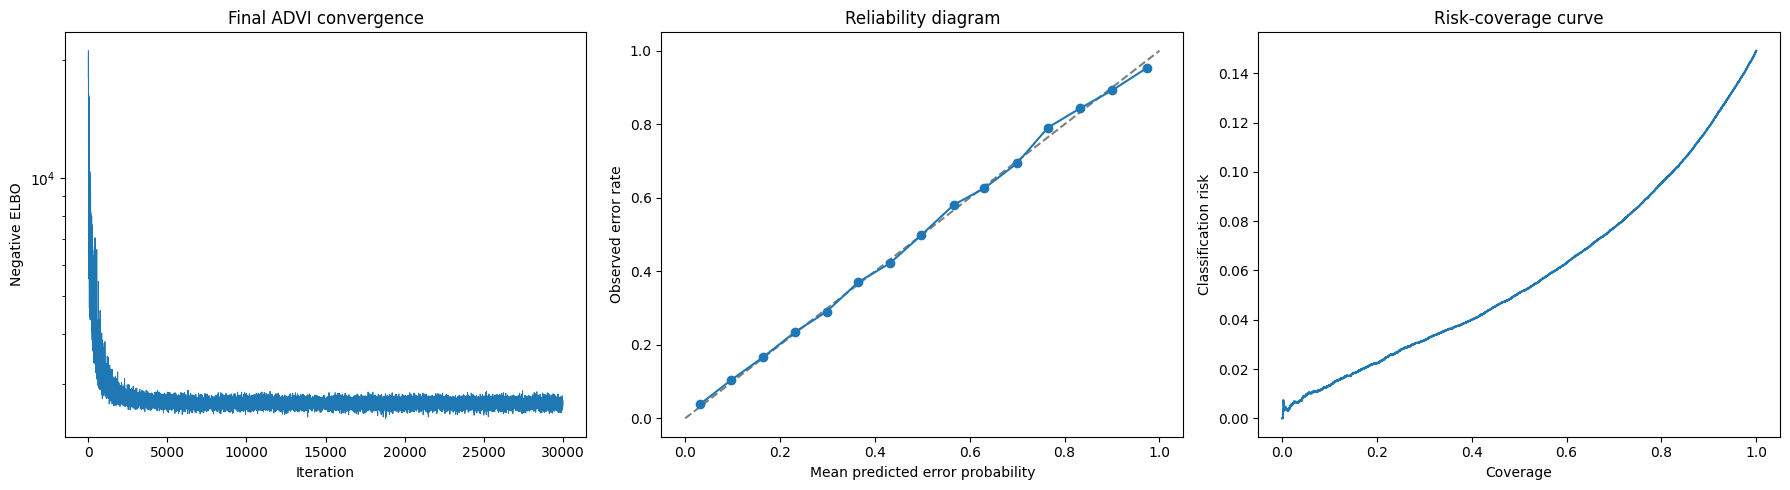

Final AUROC:  0.813907
Final PR-AUC:  0.547041
Final F1@0.50: 0.400187
Final Brier:   0.110710
Final NLL:     0.360036
Final ECE:     0.006367
Final AURC:    0.058731


In [41]:
# Score and visualize the official development predictions.
# The three panels diagnose optimization, calibration, and the tradeoff between
# automated coverage and classification risk.

final_metrics, final_reliability, final_risk_coverage = complete_metrics(
    dev_labels,
    final_probability,
)
# Attach run metadata and optimization diagnostics to predictive metrics.
final_metrics.update(
    {
        "model": "Final hierarchical Bayesian logistic",
        "configuration": FINAL_CONFIGURATION["configuration"],
        "mean_posterior_sd": float(np.mean(final_posterior_sd)),
        "runtime_seconds": final_runtime_seconds,
        "final_advi_loss": float(final_loss_history[-1]),
        "mean_last_1000_advi_loss": float(np.mean(final_loss_history[-1000:])),
    }
)
final_metrics_table = pd.DataFrame([final_metrics])
display(final_metrics_table.T)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Negative ELBO should fall rapidly and then stabilize; absolute scale is dataset-dependent.
axes[0].plot(final_loss_history, linewidth=0.7)
axes[0].set_yscale("log")
axes[0].set_title("Final ADVI convergence")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Negative ELBO")

# Perfect calibration lies on the 45-degree reference line.
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].plot(
    final_reliability["mean_probability"],
    final_reliability["observed_error_rate"],
    marker="o",
)
axes[1].set_title("Reliability diagram")
axes[1].set_xlabel("Mean predicted error probability")
axes[1].set_ylabel("Observed error rate")

# A useful abstention score keeps risk low as coverage increases.
axes[2].plot(final_risk_coverage["coverage"], final_risk_coverage["risk"])
axes[2].set_title("Risk-coverage curve")
axes[2].set_xlabel("Coverage")
axes[2].set_ylabel("Classification risk")
plt.tight_layout()
FINAL_DIAGNOSTIC_FIGURE_PATH = (
    PROCESSED_DIR / "fr_en_final_bayesian_diagnostics.png"
)
plt.savefig(
    FINAL_DIAGNOSTIC_FIGURE_PATH,
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print(f"Final AUROC:  {final_metrics['auroc']:.6f}")
print(f"Final PR-AUC:  {final_metrics['pr_auc']:.6f}")
print(f"Final F1@0.50: {final_metrics['f1_at_050']:.6f}")
print(f"Final Brier:   {final_metrics['brier']:.6f}")
print(f"Final NLL:     {final_metrics['log_loss']:.6f}")
print(f"Final ECE:     {final_metrics['ece']:.6f}")
print(f"Final AURC:    {final_metrics['aurc']:.6f}")


## 8. Save reproducible final artifacts

> Saved artifacts include predictions, posterior draws, preprocessing state,
> diagnostic tables, loss history, and a manifest sufficient to identify the run.


In [42]:
# Save a fully reproducible artifact bundle.
# A content-derived signature ties predictions and posterior files to the exact
# feature set, hyperparameters, spline knots, and training-file version.

final_signature_payload = {
    "configuration": FINAL_CONFIGURATION,
    "feature_blocks": ENABLED_FEATURE_BLOCKS,
    "extensions": ENABLED_BAYESIAN_EXTENSIONS,
    "excluded_numeric": EXCLUDED_NUMERIC_FEATURES,
    "excluded_categorical": EXCLUDED_CATEGORICAL_FEATURES,
    "numeric_columns": final_numeric_columns,
    "categorical_columns": final_categorical_columns,
    "knots": final_knot_manifest,
    "train_size": TRAIN_PATH.stat().st_size,
    "train_mtime_ns": TRAIN_PATH.stat().st_mtime_ns,
}
# The short hash prevents artifacts from incompatible runs being mixed together.
FINAL_SIGNATURE = hashlib.sha1(
    json.dumps(final_signature_payload, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
FINAL_PREFIX = PROCESSED_DIR / f"fr_en_final_bayesian_{FINAL_SIGNATURE}"

FINAL_IDATA_PATH = Path(str(FINAL_PREFIX) + "_posterior.nc")
FINAL_PREDICTION_PATH = Path(str(FINAL_PREFIX) + "_predictions.parquet")
FINAL_PRED_PATH = Path(str(FINAL_PREFIX) + ".pred")
FINAL_METRICS_PATH = Path(str(FINAL_PREFIX) + "_metrics.csv")
FINAL_RELIABILITY_PATH = Path(str(FINAL_PREFIX) + "_reliability.csv")
FINAL_RISK_COVERAGE_PATH = Path(str(FINAL_PREFIX) + "_risk_coverage.parquet")
FINAL_PIPELINE_PATH = Path(str(FINAL_PREFIX) + "_numeric_pipeline.joblib")
FINAL_MANIFEST_PATH = Path(str(FINAL_PREFIX) + "_manifest.json")
FINAL_LOSS_PATH = Path(str(FINAL_PREFIX) + "_advi_loss.npy")

# NetCDF preserves labeled posterior dimensions for later ArviZ analysis.
az.to_netcdf(final_idata, FINAL_IDATA_PATH)
joblib.dump(final_numeric_pipeline, FINAL_PIPELINE_PATH)
np.save(FINAL_LOSS_PATH, final_loss_history)

# Save both point predictions and a compact uncertainty summary per token.
final_predictions = pd.DataFrame(
    {
        "instance_id": final_dev_features["instance_id"],
        "label": dev_labels,
        "probability": final_probability,
        "posterior_sd": final_posterior_sd,
        # These are normal-approximation intervals, not exact posterior quantiles.
        "normal_lower_95": np.clip(
            final_probability - 1.96 * final_posterior_sd, 0.0, 1.0
        ),
        "normal_upper_95": np.clip(
            final_probability + 1.96 * final_posterior_sd, 0.0, 1.0
        ),
    }
)
final_predictions.to_parquet(FINAL_PREDICTION_PATH, index=False)
final_predictions[["instance_id", "probability"]].to_csv(
    FINAL_PRED_PATH,
    sep=" ",
    header=False,
    index=False,
)
final_metrics_table.to_csv(FINAL_METRICS_PATH, index=False)
final_reliability.to_csv(FINAL_RELIABILITY_PATH, index=False)
final_risk_coverage.to_parquet(FINAL_RISK_COVERAGE_PATH, index=False)

# The manifest records enough information to audit and locate every saved artifact.
final_manifest = {
    **final_signature_payload,
    "signature": FINAL_SIGNATURE,
    "global_training_error_rate": final_global_mean,
    "category_levels": final_category_levels,
    "artifacts": {
        "posterior": str(FINAL_IDATA_PATH),
        "predictions": str(FINAL_PREDICTION_PATH),
        "submission_predictions": str(FINAL_PRED_PATH),
        "metrics": str(FINAL_METRICS_PATH),
        "reliability": str(FINAL_RELIABILITY_PATH),
        "risk_coverage": str(FINAL_RISK_COVERAGE_PATH),
        "diagnostic_figure": str(FINAL_DIAGNOSTIC_FIGURE_PATH),
        "numeric_pipeline": str(FINAL_PIPELINE_PATH),
        "advi_loss": str(FINAL_LOSS_PATH),
    },
}
FINAL_MANIFEST_PATH.write_text(
    json.dumps(final_manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for path in [
    FINAL_IDATA_PATH,
    FINAL_PREDICTION_PATH,
    FINAL_PRED_PATH,
    FINAL_METRICS_PATH,
    FINAL_RELIABILITY_PATH,
    FINAL_RISK_COVERAGE_PATH,
    FINAL_DIAGNOSTIC_FIGURE_PATH,
    FINAL_PIPELINE_PATH,
    FINAL_MANIFEST_PATH,
    FINAL_LOSS_PATH,
]:
    print(path)


C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028_posterior.nc
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028_predictions.parquet
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028.pred
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028_metrics.csv
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028_reliability.csv
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_f20f975ad028_risk_coverage.parquet
C:\Users\Richard\Desktop\school\Bayesian Machine Learning\project\english - french\processed\fr_en_final_bayesian_diagnostics.png
C:\Users\Richard\Des

## Reporting rule

These official development results are the final held-out results for the
selected model. Do not use them to alter the configuration or select a new
probability threshold. If a deployment threshold is required, estimate it from
the within-user confirmation predictions and report the threshold-selection
rule separately.


### Final Conclusion

The selected hierarchical Bayesian logistic model achieved an AUROC of 0.814 and PR-AUC of 0.547 on the official development set. It was well calibrated, with an ECE of 0.006 and Brier score of 0.111. Selective prediction improved accuracy to 90.46% when the model retained its 80% most confident predictions. Compared with regularized logistic regression, the Bayesian model improved discrimination, calibration, probability accuracy, and risk-coverage performance.